In [1]:
!cd src && make clean && make

rm -f ../build/*.o ../build/libdensity.so
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c density_evolution.c -o ../build/density_evolution.o
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c progress_bar.c -o ../build/progress_bar.o
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c density_evolution_poly.c -o ../build/density_evolution_poly.o
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c differential_evolution_poly_find.c -o ../build/differential_evolution_poly_find.o
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c differential_evolution_prefect_border_find.c -o ../build/differential_evolution_prefect_border_find.o
clang -shared -L/opt/homebrew/opt/libomp/lib -lomp -o ../build/libdensity.so ../build/density_evol

In [2]:
from matplotlib import pyplot as plt
from tqdm import tqdm
from itertools import product
import ctypes
import numpy as np
from decoding_limit import decoding_limit

# Загрузка библиотеки
lib = ctypes.CDLL('build/libdensity.so')

# Прототип функции (нужно один раз задать типы аргументов)
lib.density_evolution_bec_irregular.argtypes = [
    ctypes.c_longdouble,                        # epsilon
    ctypes.c_longdouble,                        # delta
    ctypes.POINTER(ctypes.c_int),               # dv
    ctypes.POINTER(ctypes.c_int),               # dc
    ctypes.POINTER(ctypes.c_longdouble),        # lambda
    ctypes.POINTER(ctypes.c_longdouble),        # rho
    ctypes.c_int,                               # dv_size
    ctypes.c_int,                               # dc_size
    ctypes.c_int,                               # num_iters
    ctypes.POINTER(ctypes.c_longdouble),        # p0_out
    ctypes.POINTER(ctypes.c_longdouble),        # p_minus_out
    ctypes.POINTER(ctypes.c_longdouble)         # p_plus_out
]

def density_evolution_bec_irregular(epsilon, delta, lmbd: dict, rho: dict, num_iters: int):
    """
    Обёртка над C-функцией density_evolution_bec_irregular.

    Аргументы:
        epsilon (float): вероятность стирания в канале (BEC)
        delta (float): вероятность ошибки замены (bit-flip)
        lmbd (dict): распределение степеней переменных, например {2: 0.5, 3: 0.5}
        rho (dict): распределение степеней проверочных узлов, например {6: 1.0}
        num_iters (int): количество итераций

    Возвращает:
        (p0_list, p_minus_list, p_plus_list) — numpy-массивы длины num_iters+1
    """
    # Преобразуем словари в массивы степеней и коэффициентов
    dv_keys = sorted(lmbd.keys())
    dc_keys = sorted(rho.keys())
    
    dv = (ctypes.c_int * len(dv_keys))(*dv_keys)
    dc = (ctypes.c_int * len(dc_keys))(*dc_keys)
    
    lambda_arr = (ctypes.c_longdouble * len(dv_keys))(*[lmbd[k] for k in dv_keys])
    rho_arr = (ctypes.c_longdouble * len(dc_keys))(*[rho[k] for k in dc_keys])

    # Выделяем выходные массивы
    size = num_iters + 1
    p0_out = (ctypes.c_longdouble * size)()
    p_minus_out = (ctypes.c_longdouble * size)()
    p_plus_out = (ctypes.c_longdouble * size)()

    # Вызов C-функции
    lib.density_evolution_bec_irregular(
        ctypes.c_longdouble(epsilon),
        ctypes.c_longdouble(delta),
        dv,
        dc,
        lambda_arr,
        rho_arr,
        ctypes.c_int(len(dv_keys)),
        ctypes.c_int(len(dc_keys)),
        ctypes.c_int(num_iters),
        p0_out,
        p_minus_out,
        p_plus_out
    )

    # Преобразуем результаты в numpy-массивы
    return (
        np.frombuffer(p0_out, dtype=np.longdouble, count=size).copy(),
        np.frombuffer(p_minus_out, dtype=np.longdouble, count=size).copy(),
        np.frombuffer(p_plus_out, dtype=np.longdouble, count=size).copy()
    )

# Прототип функции
lib.density_evolution_grid_irregular.argtypes = [
    ctypes.POINTER(ctypes.c_longdouble),  # p0_vals
    ctypes.c_int,                         # n_p0
    ctypes.c_longdouble,                  # p_minus_limit
    ctypes.c_int,                         # p_minus_max_iter
    ctypes.POINTER(ctypes.c_int),         # dv
    ctypes.POINTER(ctypes.c_int),         # dc
    ctypes.POINTER(ctypes.c_longdouble),  # lambda
    ctypes.POINTER(ctypes.c_longdouble),  # rho
    ctypes.c_int,                         # dv_size
    ctypes.c_int,                         # dc_size
    ctypes.c_int,                         # num_iters
    ctypes.c_longdouble,                  # threshold
    ctypes.c_int,                         # is_progress_visible
    np.ctypeslib.ndpointer(dtype=ctypes.c_longdouble, flags="C_CONTIGUOUS")   # results
]

def density_evolution_grid_irregular(p0_vals, p_minus_limit, p_minus_max_iters, lmbd: dict, rho: dict, num_iters: int, threshold: float, is_progress_visible: bool=True):
    """
    Обёртка над C-функцией density_evolution_grid_irregular.
    """
    # Преобразуем входы
    p0_vals = np.asarray(p0_vals, dtype=np.longdouble)
    n_p0 = len(p0_vals)

    # Преобразуем словари степеней
    dv_keys = sorted(lmbd.keys())
    dc_keys = sorted(rho.keys())

    dv = (ctypes.c_int * len(dv_keys))(*dv_keys)
    dc = (ctypes.c_int * len(dc_keys))(*dc_keys)
    
    lambda_arr = (ctypes.c_longdouble * len(dv_keys))(*[lmbd[k] for k in dv_keys])
    rho_arr = (ctypes.c_longdouble * len(dc_keys))(*[rho[k] for k in dc_keys])

    # Указатели на p0 и p_minus
    p0_ptr = p0_vals.ctypes.data_as(ctypes.POINTER(ctypes.c_longdouble))

    # Выходной массив результатов
    results = np.full(len(p0_vals), -1, dtype=ctypes.c_longdouble)

    # Вызов функции
    lib.density_evolution_grid_irregular(
        p0_ptr,
        ctypes.c_int(n_p0),
        ctypes.c_longdouble(p_minus_limit),
        ctypes.c_int(p_minus_max_iters),
        dv,
        dc,
        lambda_arr,
        rho_arr,
        ctypes.c_int(len(dv_keys)),
        ctypes.c_int(len(dc_keys)),
        ctypes.c_int(num_iters),
        ctypes.c_longdouble(threshold),
        ctypes.c_int(int(is_progress_visible)),
        results
    )

    # Преобразование в 2D NumPy-массив
    return results

Grid search: 100%|██████████| 250000/250000 [00:04<00:00, 57486.22it/s]


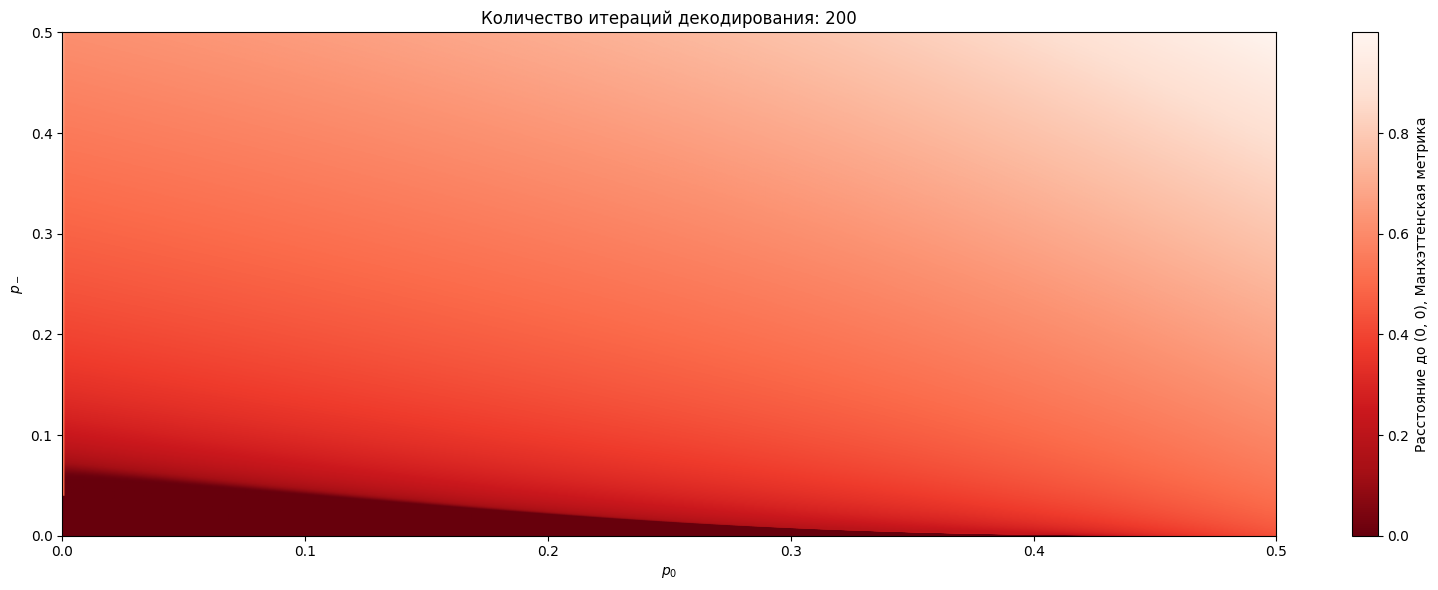

In [ ]:
p0_lim = np.float64(0)
p_minus_lim = np.float64(0)

p0_vals = np.linspace(0, 0.5, 500, dtype=np.float64)
p_minus_vals = np.linspace(0, 0.5, 500, dtype=np.float64)
p_heat = []

p_heat = []
for p0, p_minus in tqdm(product(p0_vals, p_minus_vals), total=len(p0_vals)*len(p_minus_vals), desc="Grid search"):
    if p0 + p_minus <= 1:
        p0_example, p_minus_example, p_plus_example = density_evolution_bec_irregular(
            epsilon=p0,
            delta=p_minus,
            rho={6: 1},
            lmbd={3: 1},
            num_iters=20
        )
    else:
        p0_example, p_minus_example = [0.5], [0.5]
    p_heat.append(p0_example[-1] + p_minus_example[-1])

# Преобразуем в матрицу для тепловой карты
p_heat = np.array(p_heat).reshape(len(p0_vals), len(p_minus_vals))

# Построение графика
plt.figure(figsize=(16, 6))
plt.imshow(p_heat.T, origin='lower', extent=(p0_vals[0], p0_vals[-1], p_minus_vals[0], p_minus_vals[-1]),
           aspect='auto', cmap='Reds_r')
plt.colorbar(label='Расстояние до (0, 0), Манхэттенская метрика')
plt.title('Количество итераций декодирования: 200')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.tight_layout()
plt.savefig("heatmap.png")

Grid search: 100%|██████████| 19600/19600 [00:19<00:00, 1023.93it/s]


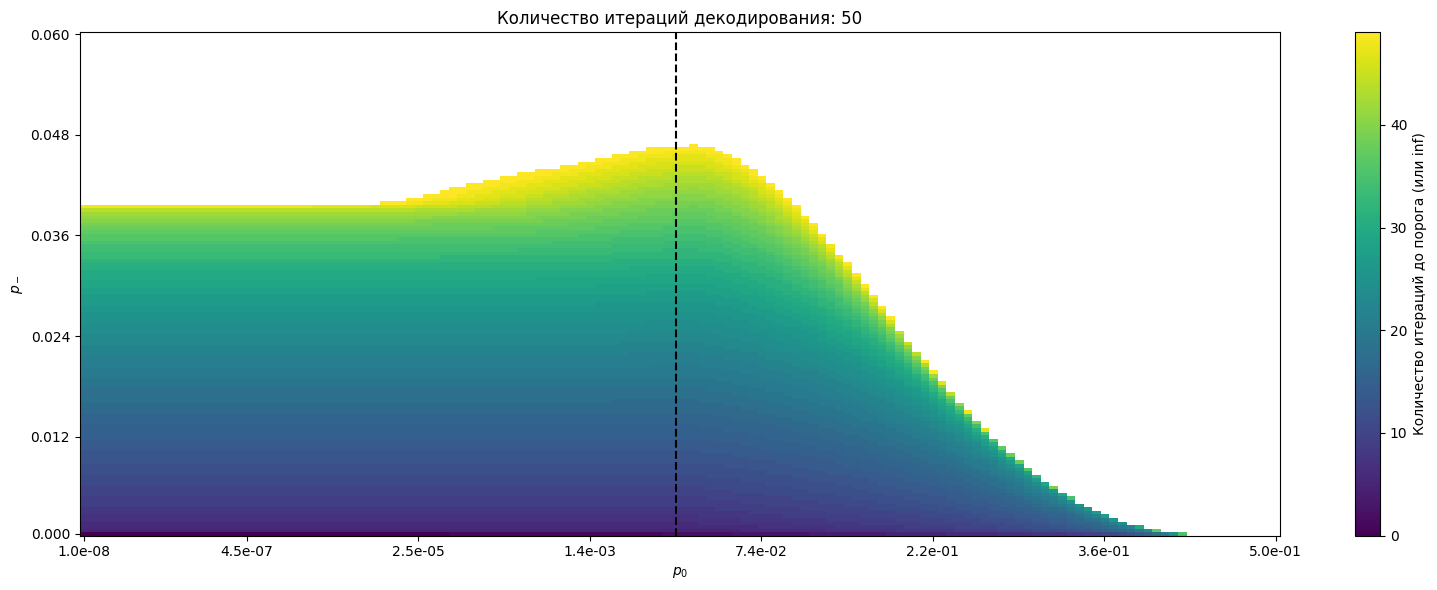

In [46]:
p0_lim = np.float64(0)
p_minus_lim = np.float64(0)

p0_vals = np.hstack([np.logspace(-8, -2, 70), np.linspace(1e-2, 0.5, 70, dtype=np.float64)])
p_minus_vals = np.linspace(0, 0.06, 140, dtype=np.float64)
threshold = 1e-15

p_heat = []
for p0, p_minus in tqdm(product(p0_vals, p_minus_vals), total=len(p0_vals)*len(p_minus_vals), desc="Grid search"):
    p0_example, p_minus_example = [], []
    for i in range(1, 51):
        if p0 + p_minus <= 1:
            p0_example_cur, p_minus_example_cur, p_plus_example_cur = density_evolution_bec_irregular(
                epsilon=p0,
                delta=p_minus,
                rho={6: 1},
                lmbd={3: 1},
                num_iters=i
            )
        else:
            p0_example_cur, p_minus_example_cur = [0.5], [0.5]
        p0_example.append(p0_example_cur[-1])
        p_minus_example.append(p_minus_example_cur[-1])
    p_heat.append(next(iter(np.where((np.array(p0_example) + np.array(p_minus_example)) < threshold)[0]), float('inf')))

# Преобразуем в матрицу для тепловой карты
p_heat = np.array(p_heat).reshape(len(p0_vals), len(p_minus_vals))

plt.figure(figsize=(16, 6))
plt.imshow(p_heat.T, origin='lower', aspect='auto')  # равномерный масштаб по обеим осям

# делаем подписи осей по реальным значениям сетки
n_xticks = 8   # сколько подписей по оси p0
n_yticks = 6   # сколько подписей по оси p_minus

xtick_idx = np.linspace(0, len(p0_vals)-1, n_xticks, dtype=int)
ytick_idx = np.linspace(0, len(p_minus_vals)-1, n_yticks, dtype=int)

plt.xticks(xtick_idx, [f"{p0_vals[i]:.1e}" for i in xtick_idx])   # экспоненциальный формат
plt.yticks(ytick_idx, [f"{p_minus_vals[i]:.3f}" for i in ytick_idx])

x_val = 1e-2
x_idx = np.argmin(np.abs(p0_vals - x_val))  # индекс ближайшего к 1e-2
plt.axvline(x_idx, color='k', linestyle='--')

plt.colorbar(label='Количество итераций до порога (или inf)')
plt.title('Количество итераций декодирования: 50')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.tight_layout()
plt.show()

In [48]:
import numpy as np

# заменяем inf на -1 для удобного сохранения
p_heat_out = np.where(np.isinf(p_heat), -1, p_heat).astype(int)

grid = np.column_stack([
    np.repeat(p0_vals, len(p_minus_vals)),
    np.tile(p_minus_vals, len(p0_vals)),
    p_heat_out.flatten()
])

np.savetxt(
    "grid_results.txt",
    grid,
    header="p0 p_minus p_heat (-1 = inf)",
    fmt=["%.6e", "%.6f", "%d"],
    delimiter="\t"
)

Progress: [##############################################    ] 93%

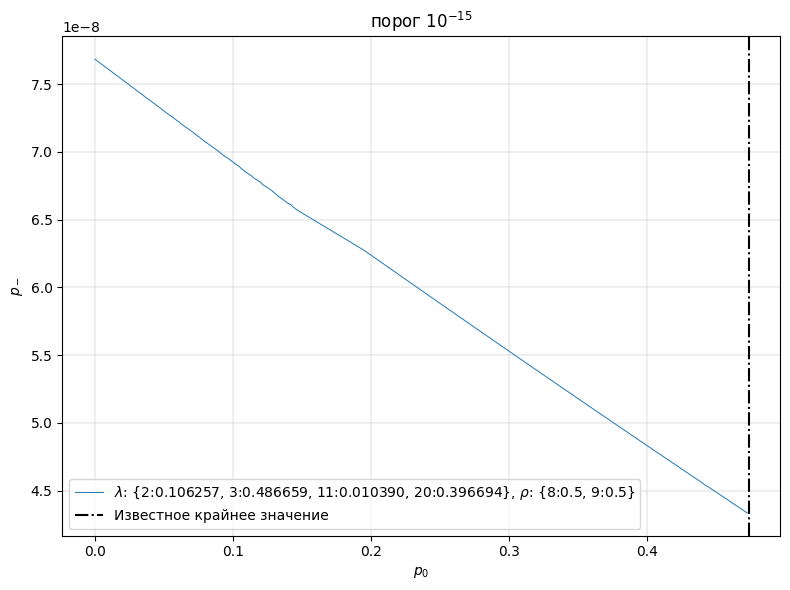

In [11]:
# Сетка значений
p0_vals = np.concatenate([
    np.logspace(-20, -3, 250, dtype=np.float64),
    np.linspace(1e-3, 0.55, 250, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 500, dtype=np.float64)

threshold = 1e-15

num_iters = 500

results = density_evolution_grid_irregular(p0_vals, p_minus_vals[-1], 100, {2:0.106257, 3:0.486659, 11:0.010390, 20:0.396694}, {8:0.5, 9:0.5}, num_iters, threshold)

mask = results > -1
points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask]])

plt.figure(figsize=(8, 6))
plt.plot(points[0, :], points[1, :], label=f'$\\lambda$: {{2:0.106257, 3:0.486659, 11:0.010390, 20:0.396694}}, $\\rho$: {{8:0.5, 9:0.5}}', linewidth=0.7)
plt.axvline(0.4741, color='black', linestyle='-.', label="Известное крайнее значение")
plt.title(f'порог $10^{{{int(np.log10(threshold))}}}$')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.grid(linewidth=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("veref_irreg.png")

Progress: [############################################      ] 88%(3, 6)


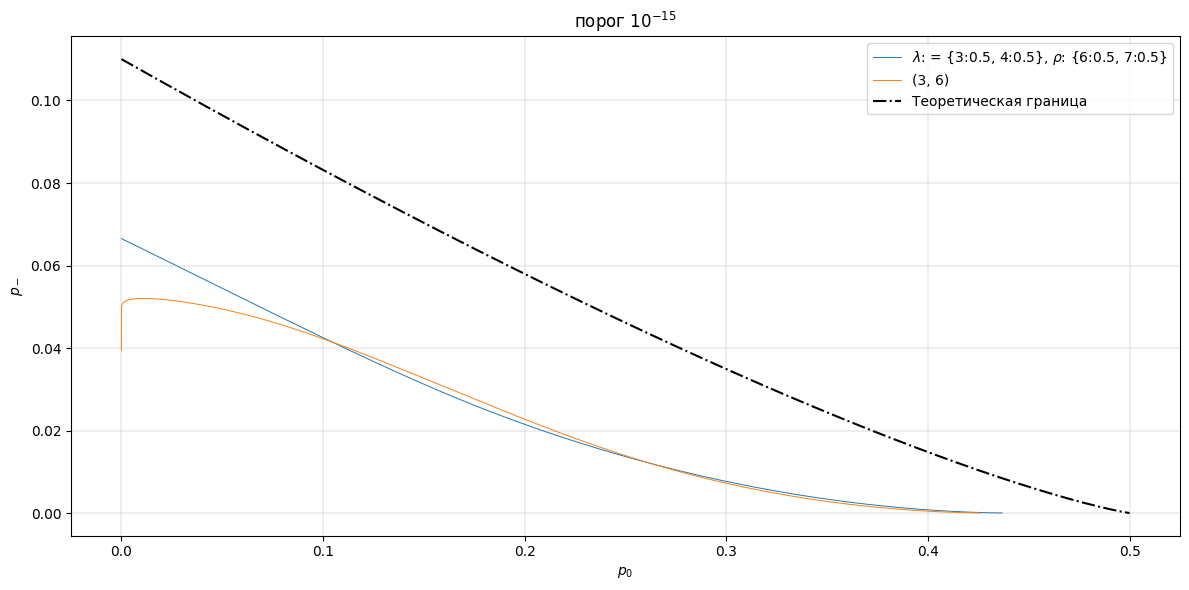

In [17]:
plt.figure(figsize=(12, 6))
# Сетка значений
p0_vals = np.concatenate([
    np.logspace(-20, -3, 1000),
    np.linspace(1e-3, 0.55, 1000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)

threshold = 1e-15

not_r = 2

num_iters = 60

results = density_evolution_grid_irregular(p0_vals, p_minus_vals[-1], 100, {3:0.5, 4:0.5}, {6:0.5, 7:0.5}, num_iters, threshold)

mask = results > -1
points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask]])
plt.plot(points[0, :], points[1, :], label=f'$\\lambda$: = {{3:0.5, 4:0.5}}, $\\rho$: {{6:0.5, 7:0.5}}', linewidth=0.7)

for l in range(3, 4):
    results = density_evolution_grid_irregular(p0_vals, p_minus_vals[-1], 100, {l:1}, {(not_r*l):1}, num_iters, threshold)

    print(f'({l}, {l*not_r})')
    mask = results > -1
    points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
    plt.plot(points[0, :], points[1, :], label=f'({l}, {l*not_r})', linewidth=0.7)

plt.plot(*decoding_limit(), label="Теоретическая граница", color='black', linestyle='-.')
plt.title(f'порог $10^{{{int(np.log10(threshold))}}}$')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.grid(linewidth=0.3)
plt.legend()
plt.tight_layout()